### Load Airport and Airline Abbreviations

### Loading and Combining airport-airline wise CSVs into a single airport wise df

In [22]:
import pandas as pd
alaska_atl = pd.read_csv(r"data\atl-atlanta\alaska_atl_2025.csv")
american_atl = pd.read_csv(r"data\atl-atlanta\american_atl_2025.csv")
delta_atl = pd.read_csv(r"data\atl-atlanta\delta_atl_2025.csv")
frontier_atl = pd.read_csv(r"data\atl-atlanta\frontier_atl_2025.csv")
jetblue_atl = pd.read_csv(r"data\atl-atlanta\jetblue_atl_2025.csv")
southwest_atl = pd.read_csv(r"data\atl-atlanta\southwest_atl_2025.csv")
united_atl = pd.read_csv(r"data\atl-atlanta\united_atl_2025.csv")

alaska_lax= pd.read_csv(r"data\lax-los-angeles\alaska_lax_2025.csv")
american_lax = pd.read_csv(r"data\lax-los-angeles\american_lax_2025.csv")
delta_lax = pd.read_csv(r"data\lax-los-angeles\delta_lax_2025.csv")
frontier_lax = pd.read_csv(r"data\lax-los-angeles\frontier_lax_2025.csv")
jetblue_lax = pd.read_csv(r"data\lax-los-angeles\jetblue_lax_2025.csv") 
southwest_lax = pd.read_csv(r"data\lax-los-angeles\southwest_lax_2025.csv")
united_lax = pd.read_csv(r"data\lax-los-angeles\united_lax_2025.csv")

atlanta_airlines_list=[alaska_atl, american_atl, delta_atl, frontier_atl, jetblue_atl, southwest_atl, united_atl]
la_airlines_list=[alaska_lax, american_lax, delta_lax, frontier_lax, jetblue_lax, southwest_lax, united_lax]

In [29]:
atlanta_airlines= pd.concat(
    [
        alaska_atl,
        american_atl,
        delta_atl,
        frontier_atl,
        jetblue_atl,
        southwest_atl,
        united_atl,
    ],
    ignore_index=True,
)

# Insert Origin Airport between Tail Number and Destination Airport
atlanta_airlines.insert(
    atlanta_airlines.columns.get_loc("Destination Airport"),
    "Origin Airport",
    "ATL",
)

####

la_airlines= pd.concat(
    [
        alaska_lax,
        american_lax,
        delta_lax,
        frontier_lax,
        jetblue_lax,
        southwest_lax,
        united_lax,
    ],
    ignore_index=True,
)   

# Insert Origin Airport between Tail Number and Destination Airport
la_airlines.insert(
    la_airlines.columns.get_loc("Destination Airport"),
    "Origin Airport",
    "LAX",
)

atlanta_airlines.head()


,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,18:53,17,0,0,0,0,0
1,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,17:35,19,0,0,0,0,0
2,AS,01/01/2025,377,N278AK,ATL,SEA,07:04,06:55,343,336,-9,07:11,16,0,0,0,0,0
3,AS,01/01/2025,497,N562AS,ATL,SEA,15:27,15:22,344,338,-5,15:34,12,0,0,0,0,0
4,AS,01/01/2025,783,N263AK,ATL,PDX,19:59,20:07,319,343,8,20:23,16,8,0,24,0,0


In [30]:
la_airlines.head()

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2025,6,N597AS,LAX,DCA,13:08,13:02,291,278,-6,13:21,19,0,0,0,0,0
1,AS,01/01/2025,193,N408AS,LAX,ANC,19:51,19:48,347,321,-3,20:02,14,0,0,0,0,0
2,AS,01/01/2025,284,N548AS,LAX,EWR,06:00,05:54,330,304,-6,06:14,20,0,0,0,0,0
3,AS,01/01/2025,286,N948AK,LAX,EWR,08:29,08:26,330,313,-3,08:55,29,0,0,0,0,0
4,AS,01/01/2025,288,N968AK,LAX,EWR,21:40,21:36,319,293,-4,21:52,16,0,0,0,0,0


In [24]:
print(atlanta_airlines.shape)
print(la_airlines.shape)

(292057, 18)
(140108, 18)


### Monthly Flight counts plot per airport

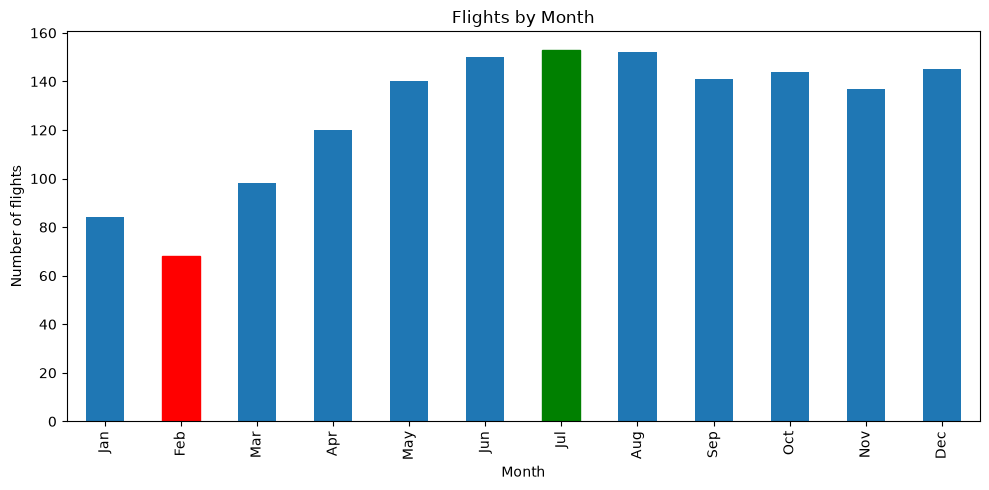

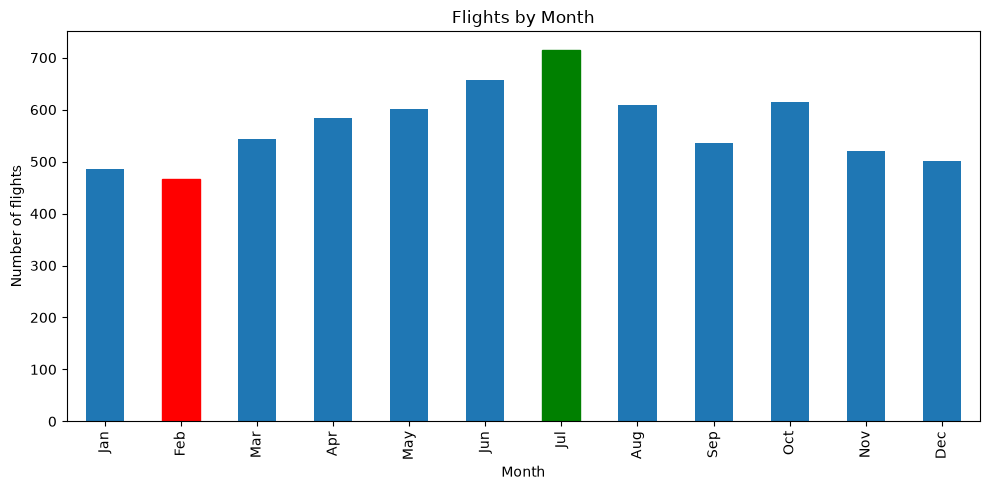

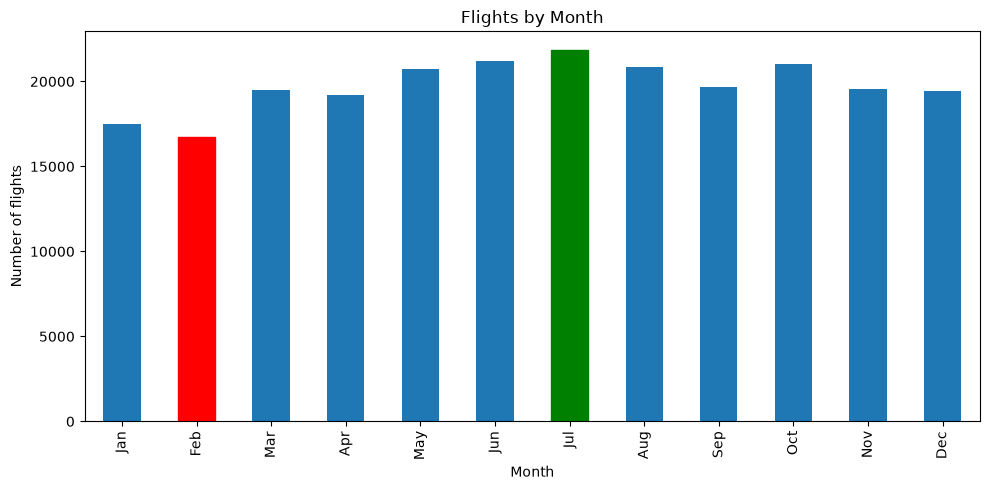

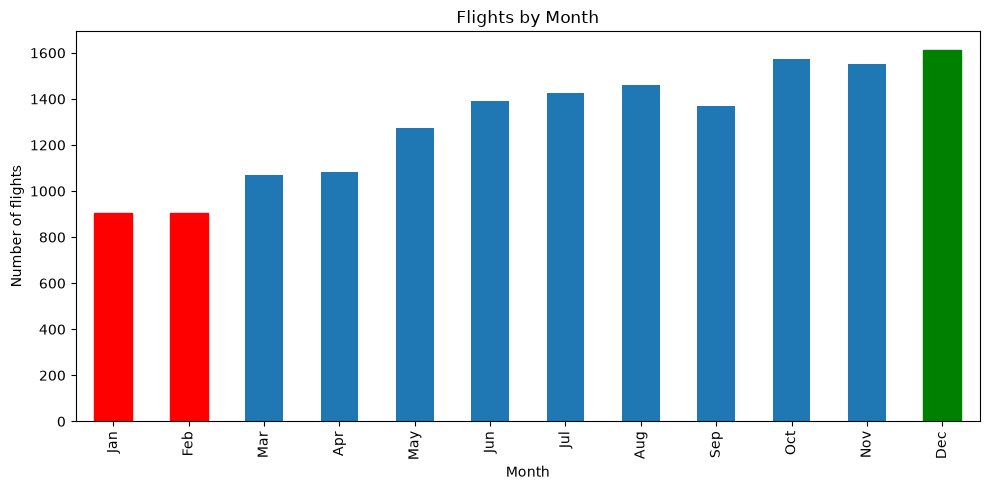

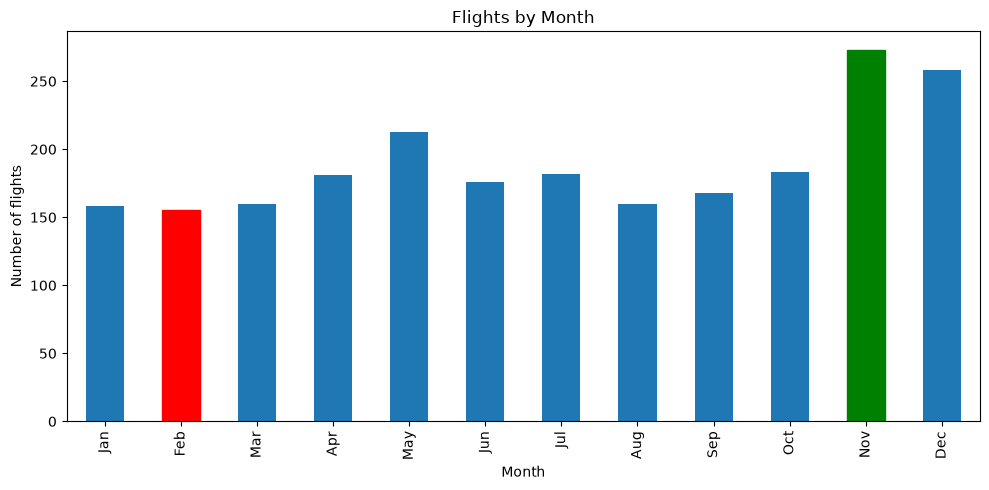

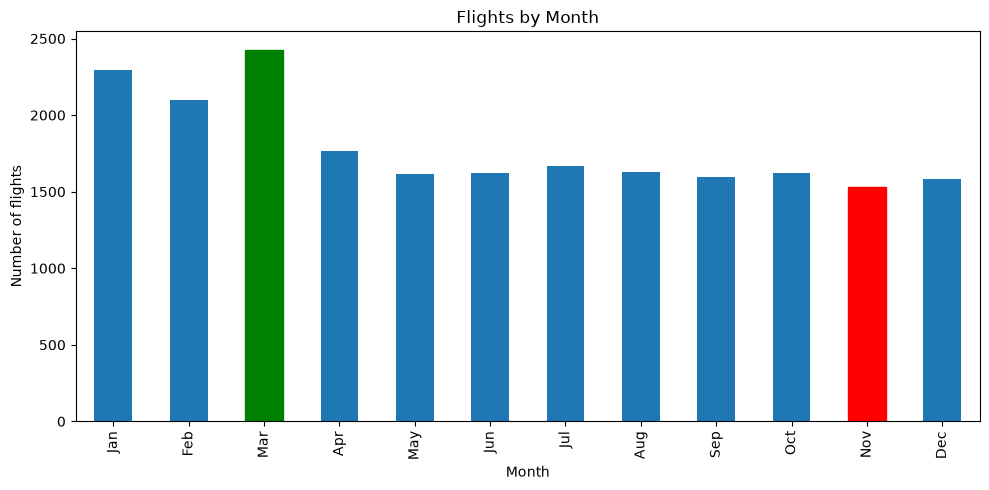

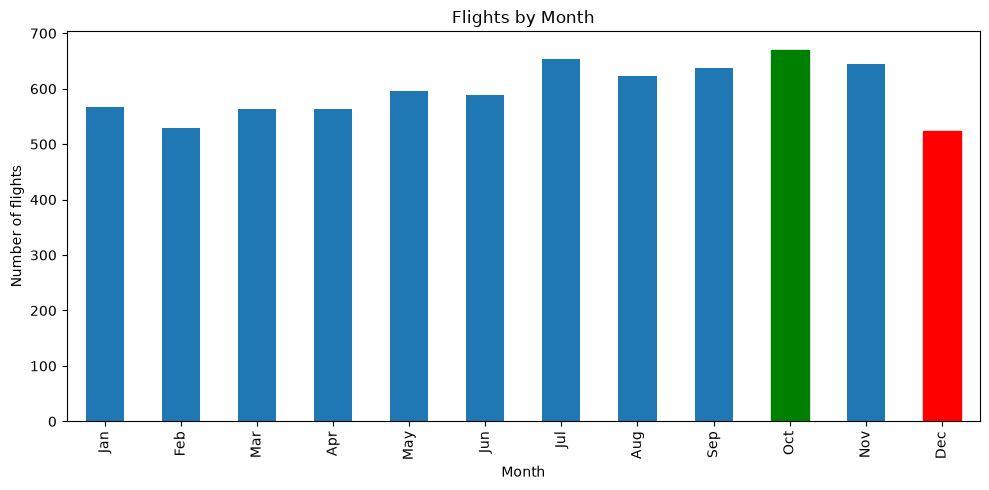

In [28]:
import matplotlib.pyplot as plt

def plot_monthly_flight_counts(df):
    dates = pd.to_datetime(df["Date (MM/DD/YYYY)"], format="%m/%d/%Y", errors="coerce")
    counts = dates.dt.month.value_counts().reindex(range(1, 13), fill_value=0)

    ax = counts.plot(kind="bar", figsize=(10, 5))
    ax.set(
        title="Flights by Month",
        xlabel="Month",
        ylabel="Number of flights",
        xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    )
    plt.tight_layout()

    min_count, max_count = counts.min(), counts.max()
    for bar, value in zip(ax.patches, counts):
        if value == max_count:
            bar.set_color("green")
        elif value == min_count:
            bar.set_color("red")
    plt.show()

# Example:
for airline_df in atlanta_airlines_list:
    plot_monthly_flight_counts(airline_df)

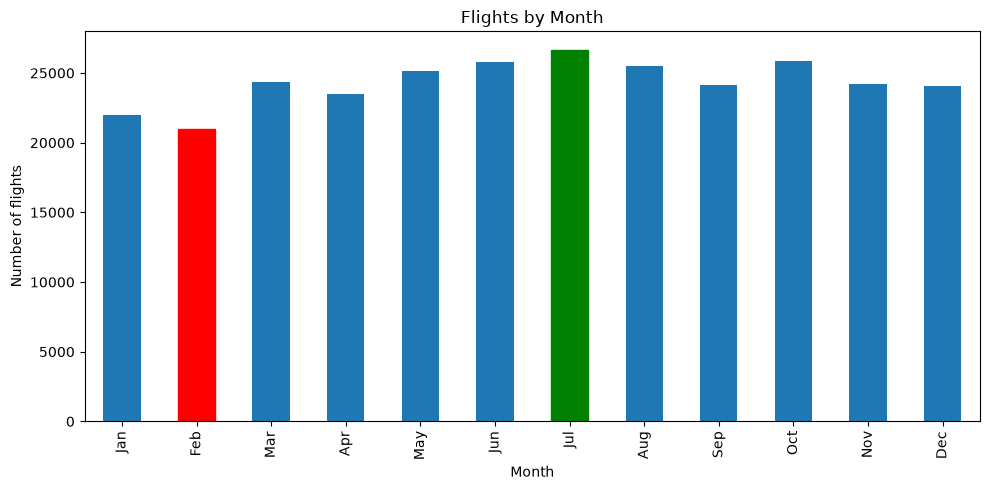

In [20]:
plot_monthly_flight_counts(atlanta_airlines)

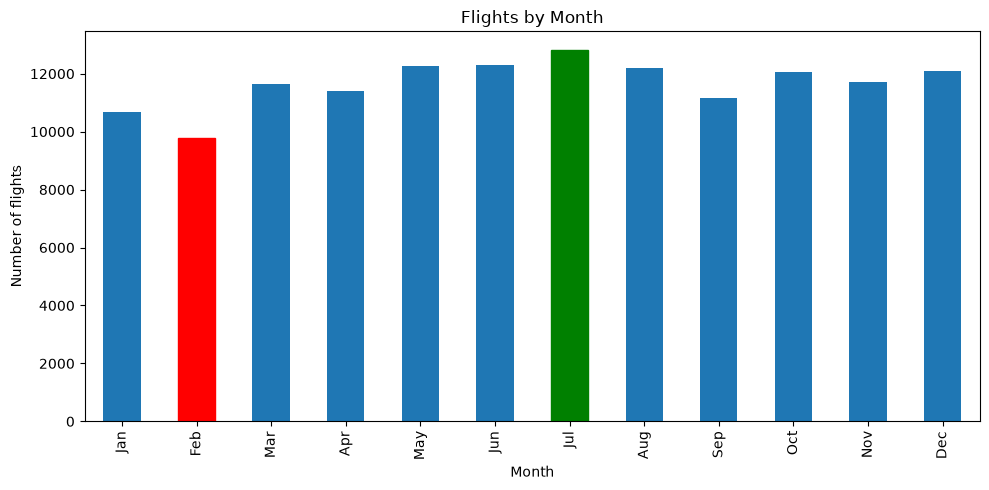

In [25]:
plot_monthly_flight_counts(la_airlines)

### Something

In [31]:
atlanta_airlines.head()

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,18:53,17,0,0,0,0,0
1,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,17:35,19,0,0,0,0,0
2,AS,01/01/2025,377,N278AK,ATL,SEA,07:04,06:55,343,336,-9,07:11,16,0,0,0,0,0
3,AS,01/01/2025,497,N562AS,ATL,SEA,15:27,15:22,344,338,-5,15:34,12,0,0,0,0,0
4,AS,01/01/2025,783,N263AK,ATL,PDX,19:59,20:07,319,343,8,20:23,16,8,0,24,0,0


In [45]:
atlanta_airlines["Destination Airport"].value_counts()

Destination Airport
MCO    7587
LGA    7024
DFW    6149
TPA    5914
MIA    5748
       ... 
BGR      29
RAP      16
FAR       5
SBN       2
SHV       1
Name: count, Length: 139, dtype: int64

In [47]:
flights_by_destination_and_carrier = (
    atlanta_airlines
    .groupby(["Destination Airport", "Carrier Code"])
    .size()
    .unstack(fill_value=0)
)

for destination, counts in flights_by_destination_and_carrier.iterrows():
    total = int(counts.sum())
    print(f"{destination} - total {total}")

    for carrier, count in counts[counts > 0].sort_values(
        ascending=False
    ).items():
        print(f"  {carrier} - {int(count)}")

ABQ - total 996
  DL - 996
AGS - total 671
  DL - 671
ALB - total 1047
  DL - 1047
ANC - total 133
  DL - 133
ATW - total 305
  DL - 305
AUS - total 4519
  DL - 3208
  WN - 1085
  F9 - 223
  AA - 3
AVL - total 1863
  DL - 1863
BDL - total 2300
  DL - 2172
  F9 - 128
BGR - total 29
  DL - 29
BHM - total 3079
  DL - 3079
BNA - total 4096
  DL - 3290
  WN - 806
BOI - total 513
  DL - 513
BOS - total 4756
  DL - 3598
  B6 - 920
  F9 - 238
BTR - total 912
  DL - 912
BTV - total 380
  DL - 380
BUF - total 1368
  DL - 1175
  F9 - 192
  WN - 1
BUR - total 352
  DL - 352
BWI - total 5339
  DL - 2884
  WN - 1737
  F9 - 718
BZN - total 417
  DL - 417
CAE - total 1835
  DL - 1835
CHA - total 1225
  DL - 1225
CHO - total 181
  DL - 181
CHS - total 3068
  DL - 3068
CID - total 367
  DL - 367
CLE - total 3342
  DL - 2689
  F9 - 561
  WN - 92
CLT - total 3229
  DL - 2845
  AA - 384
CMH - total 3189
  DL - 2671
  WN - 453
  F9 - 63
  AA - 1
  UA - 1
COS - total 542
  DL - 542
CVG - total 2937
  DL - 26

In [41]:
print(out)

Carrier Code  Destination Airport
AA            DFW                    2667
              MIA                    1636
              PHX                     642
              ORD                     573
              PHL                     448
                                     ... 
WN            PBI                      59
              OKC                      55
              OMA                      54
              BUF                       1
              SAN                       1
Name: count, Length: 250, dtype: int64
